# HW#00: MLP Function Approximation
*Scientific Machine Learning*

Victoria Dinov

---
# 1 Theoretical Foundations

## 1.1 The Universal Approximation Theorem

**a)** If the activation function is continuous and not a polynomial (sigmoid, tanh, and ReLU all qualify), then any continuous function on a closed, bounded region can be approximated as closely as you want by a network with a single hidden layer and a finite number of neurons. In other words, for any tolerance $\varepsilon > 0$ there's some width $N$ that gets the network within $\varepsilon$ of the function everywhere on that region.

**b)** The theorem only says a good network exists. It doesn't say how many neurons you need (for some functions that number grows exponentially with the input dimension), it doesn't guarantee that gradient descent will actually find the right weights, and it says nothing about how well the network does on data it wasn't trained on. It's also only about one hidden layer, so it doesn't explain why deeper networks often work better in practice, which comes up in Section 3.

In [1]:
import time, os
import numpy as np
import matplotlib.pyplot as plt
from scipy.stats import binom

# folder for saved plots + default plot style
os.makedirs("figs", exist_ok=True)
plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": 0.3})

# activation name -> (function, derivative). derivative gets z (pre-activation) and a (output)
# so tanh/sigmoid can reuse a instead of recomputing
ACTS = {
    "tanh":    (np.tanh,                    lambda z, a: 1.0 - a**2),
    "relu":    (lambda z: np.maximum(0, z), lambda z, a: (z > 0).astype(z.dtype)),
    "sigmoid": (lambda z: 1/(1+np.exp(-z)), lambda z, a: a*(1-a)),
}


# fully connected net, sizes = [in, hidden..., out], e.g. [1, 50, 1]
class MLP:
    def __init__(self, sizes, act="tanh", seed=0):
        rng = np.random.default_rng(seed)
        self.act, self.dact = ACTS[act]
        self.W, self.b = [], []
        # one weight matrix (m x n) + bias per pair of consecutive layers
        for i, (m, n) in enumerate(zip(sizes[:-1], sizes[1:])):
            gain = 2.0 if act == "relu" else 1.0          # He for ReLU, Xavier-ish for tanh
            self.W.append(rng.normal(0, np.sqrt(gain / m), (m, n)))
            if act == "relu" and i == 0:                  # spread ReLU kinks over the domain
                self.b.append(-self.W[0][0] * rng.uniform(0, 1, n))
            else:
                self.b.append(np.zeros(n))

    # flat list of all params (same order as the grads from backward)
    def params(self):
        return self.W + self.b

    def forward(self, x):
        # save (z, a) for every layer, backward needs them
        self.cache = [(None, x)]
        a = x
        for i, (W, b) in enumerate(zip(self.W, self.b)):
            z = a @ W + b
            # last layer is linear (no activation)
            a = z if i == len(self.W) - 1 else self.act(z)
            self.cache.append((z, a))
        return a

    __call__ = forward   # so net(x) works

    # manual backprop: dout = dLoss/dOutput, returns grads in params() order
    def backward(self, dout):
        gW, gb = [None]*len(self.W), [None]*len(self.b)
        d = dout
        for i in reversed(range(len(self.W))):   # go from last layer back to first
            z, a = self.cache[i+1]
            # chain rule through the activation (skip for the linear output layer)
            if i != len(self.W) - 1:
                d = d * self.dact(z, a)
            a_prev = self.cache[i][1]
            gW[i] = a_prev.T @ d      # dL/dW = input^T * delta
            gb[i] = d.sum(0)          # dL/db = delta summed over samples
            d = d @ self.W[i].T       # pass the gradient back to the previous layer
        return gW + gb


# returns (loss value, dLoss/dpred) for the chosen loss
def loss_and_grad(pred, y, kind="mse", delta=0.05):
    r = pred - y   # residual
    n = len(y)
    if kind == "mse":
        return np.mean(r**2), 2*r/n
    if kind == "l1":
        return np.mean(np.abs(r)), np.sign(r)/n
    if kind == "huber":
        # quadratic for small residuals, linear for big ones
        a = np.abs(r)
        L = np.where(a <= delta, 0.5*r**2, delta*(a - 0.5*delta))
        return L.mean(), np.clip(r, -delta, delta)/n
    if kind == "bce":  # pred is a logit; y in {0,1}
        p = 1/(1+np.exp(-pred))   # logit -> probability
        eps = 1e-12               # avoid log(0)
        return -np.mean(y*np.log(p+eps) + (1-y)*np.log(1-p+eps)), (p - y)/n
    raise ValueError(kind)


def train(net, x, y, steps=5000, lr=1e-3, loss="mse", lr_final=None, log_every=0):
    """Full-batch Adam. Optional cosine decay from lr to lr_final."""
    P = net.params()
    # Adam state: running mean (m) and running mean of squares (v) of each grad
    m = [np.zeros_like(p) for p in P]
    v = [np.zeros_like(p) for p in P]
    b1, b2, eps = 0.9, 0.999, 1e-8
    hist = []   # loss at every step
    for t in range(1, steps+1):
        # cosine schedule: lr at the start, slides smoothly down to lr_final at the end
        cur_lr = lr if lr_final is None else lr_final + 0.5*(lr-lr_final)*(1+np.cos(np.pi*t/steps))
        # forward on all the data, then backprop
        L, d = loss_and_grad(net(x), y, loss)
        G = net.backward(d)
        # Adam update, done in place on each param array
        for p, g, mi, vi in zip(P, G, m, v):
            mi *= b1; mi += (1-b1)*g
            vi *= b2; vi += (1-b2)*g*g
            p -= cur_lr * (mi/(1-b1**t)) / (np.sqrt(vi/(1-b2**t)) + eps)   # bias-corrected step
        hist.append(L)
        if log_every and t % log_every == 0:
            print(f"step {t:6d}  loss {L:.3e}")
    return np.array(hist)


# BCE nets output logits, so squash them to [0,1] before using them as predictions
def predict(net, x, loss="mse"):
    out = net(x)
    return 1/(1+np.exp(-out)) if loss == "bce" else out

## 1.2 Bernstein Polynomials and a ReLU Network

$B_nf(x)=\sum_{k=0}^{n} f(k/n)\binom{n}{k}x^k(1-x)^{n-k}$. Each term is just a binomial probability, so I compute it with `scipy.stats.binom.pmf`, which stays stable even at $n=256$ where the binomial coefficients get huge. All errors are max errors over a 2001-point grid.

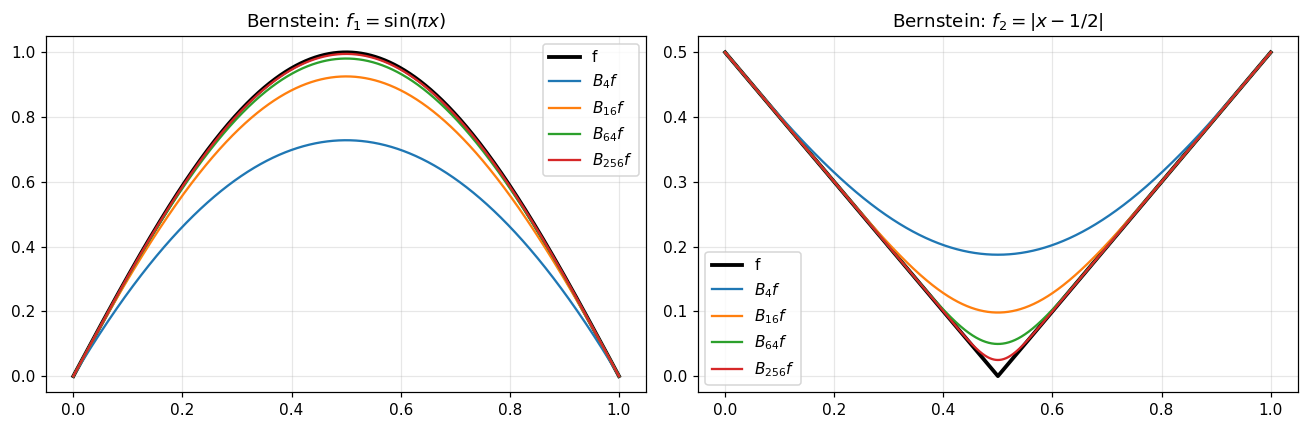

    n |  max|f1-Bn f1| |  max|f2-Bn f2|
    4 |      2.714e-01 |      1.875e-01
   16 |      7.432e-02 |      9.819e-02
   64 |      1.909e-02 |      4.967e-02
  256 |      4.808e-03 |      2.491e-02


In [2]:
# the two test functions: smooth one and one with a kink at 0.5
f1 = lambda x: np.sin(np.pi*x)
f2 = lambda x: np.abs(x - 0.5)
funcs = {r"$f_1=\sin(\pi x)$": f1, r"$f_2=|x-1/2|$": f2}
ns = [4, 16, 64, 256]          # polynomial degrees to try
xf = np.linspace(0, 1, 2001)   # fine grid for measuring error

# B_n f(x): basis matrix (points x k) times the samples f(k/n)
def bernstein(f, n, x):
    k = np.arange(n + 1)
    return binom.pmf(k[None, :], n, x[:, None]) @ f(k / n)

# plot B_n f for each n and record the max error
bern_err = {}
fig, axs = plt.subplots(1, 2, figsize=(12, 4))
for ax, (name, f) in zip(axs, funcs.items()):
    ax.plot(xf, f(xf), "k", lw=2.5, label="f")
    bern_err[name] = []
    for n in ns:
        B = bernstein(f, n, xf)
        bern_err[name].append(np.max(np.abs(f(xf) - B)))
        ax.plot(xf, B, label=f"$B_{{{n}}}f$")
    ax.set_title("Bernstein: " + name); ax.legend()
plt.tight_layout(); plt.savefig("figs/1_2a_bernstein.png"); plt.show()

# error table
print(f"{'n':>5s} | {'max|f1-Bn f1|':>14s} | {'max|f2-Bn f2|':>14s}")
for i, n in enumerate(ns):
    print(f"{n:5d} | {list(bern_err.values())[0][i]:14.3e} | {list(bern_err.values())[1][i]:14.3e}")

**b) One-hidden-layer ReLU networks.** Each net is trained on 200 evenly spaced points with MSE loss and Adam for 20k steps, with the learning rate decaying from $10^{-2}$ to $10^{-4}$. The ReLU kinks start at random spots in $[0,1]$. Small ReLU nets are very sensitive to initialization (a width-4 net can easily get stuck with dead units), so I train 5 seeds per width and report the median max error. The plots show the median seed.

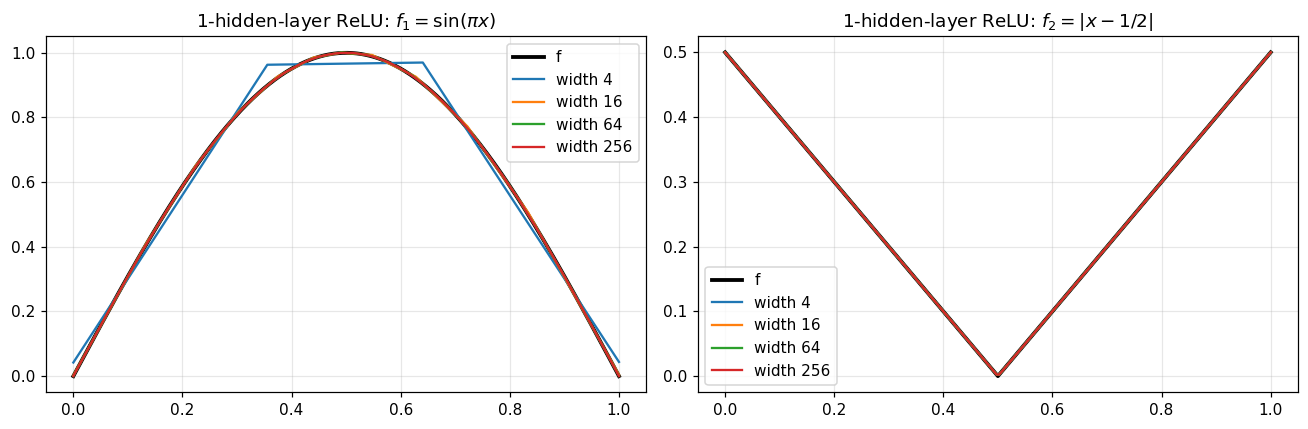

trained 40 nets in 220s

$f_1=\sin(\pi x)$
   width   4: median max-err 6.579e-02   (seeds: [0.0658 0.1596 0.0658 0.0658 0.0658])
   width  16: median max-err 6.891e-03   (seeds: [0.0093 0.0065 0.0062 0.0069 0.0083])
   width  64: median max-err 2.339e-03   (seeds: [0.0028 0.0026 0.0023 0.0021 0.0021])
   width 256: median max-err 8.242e-04   (seeds: [0.0008 0.0008 0.0012 0.0008 0.0011])
$f_2=|x-1/2|$
   width   4: median max-err 2.513e-03   (seeds: [0.2513 0.0025 0.0025 0.0078 0.001 ])
   width  16: median max-err 2.270e-03   (seeds: [0.002  0.0023 0.0023 0.0023 0.0022])
   width  64: median max-err 2.267e-03   (seeds: [0.0023 0.002  0.0023 0.0023 0.0019])
   width 256: median max-err 2.345e-03   (seeds: [0.0023 0.0022 0.0024 0.0025 0.0023])


In [3]:
xt = np.linspace(0, 1, 200)[:, None]   # 200 training points (column vector)
widths = [4, 16, 64, 256]              # same sizes as the Bernstein degrees
relu_err, relu_all = {}, {}
fig, axs = plt.subplots(1, 2, figsize=(12, 4))
t0 = time.time()
for ax, (name, f) in zip(axs, funcs.items()):
    ax.plot(xf, f(xf), "k", lw=2.5, label="f")
    relu_err[name], relu_all[name] = [], []
    for w in widths:
        # train 5 seeds per width, keep max error + prediction for each
        errs, preds = [], []
        for s in range(5):
            net = MLP([1, w, 1], "relu", seed=s)
            train(net, xt, f(xt), steps=20000, lr=1e-2, lr_final=1e-4)
            p = net(xf[:, None]).ravel(); preds.append(p)
            errs.append(np.max(np.abs(f(xf) - p)))
        # index of the median seed (3rd smallest of 5) -> report and plot that one
        med = np.argsort(errs)[2]
        relu_err[name].append(errs[med]); relu_all[name].append(errs)
        ax.plot(xf, preds[med], label=f"width {w}")
    ax.set_title("1-hidden-layer ReLU: " + name); ax.legend()
plt.tight_layout(); plt.savefig("figs/1_2b_relu.png"); plt.show()
print(f"trained 40 nets in {time.time()-t0:.0f}s\n")

# median error per width, plus all 5 seeds so I can see the bad ones
for name in funcs:
    print(name)
    for w, e, a in zip(widths, relu_err[name], relu_all[name]):
        print(f"   width {w:3d}: median max-err {e:.3e}   (seeds: {np.round(a, 4)})")

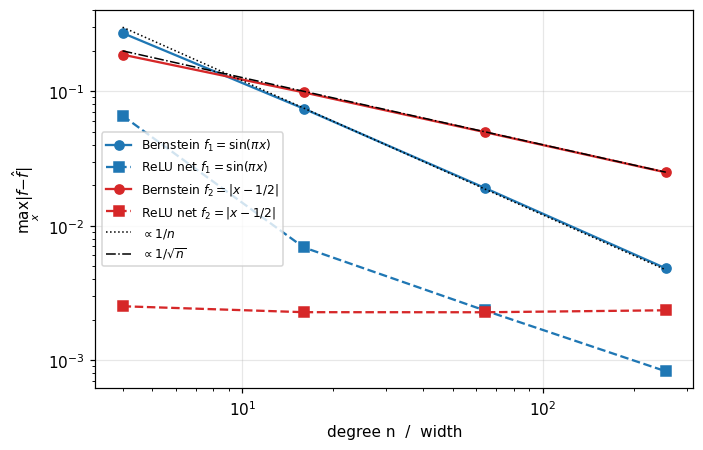

In [4]:
# log-log error vs size: Bernstein (solid) vs ReLU net (dashed), one color per function
fig, ax = plt.subplots(figsize=(6.5, 4.2))
for (name, _), c in zip(funcs.items(), ["C0", "C3"]):
    ax.loglog(ns, bern_err[name], "o-", c=c, label="Bernstein " + name)
    ax.loglog(widths, relu_err[name], "s--", c=c, label="ReLU net " + name)
# 1/n and 1/sqrt(n) reference lines to compare slopes against
nn = np.array(ns, float)
ax.loglog(nn, 1.2/nn, "k:", lw=1, label=r"$\propto 1/n$")
ax.loglog(nn, 0.4/np.sqrt(nn), "k-.", lw=1, label=r"$\propto 1/\sqrt{n}$")
ax.set_xlabel("degree n  /  width"); ax.set_ylabel(r"$\max_x|f-\hat f|$"); ax.legend(fontsize=8)
plt.tight_layout(); plt.savefig("figs/1_2c_rates.png"); plt.show()

**c) Which representation handles which function better, and why?**

Each method is best at the function that matches its own shape. Bernstein polynomials are smooth, so they did well on $f_1=\sin(\pi x)$, with the error falling roughly like $1/n$, but struggled with the kink in $f_2=|x-\tfrac12|$, where the error only fell like $1/\sqrt{n}$ (0.025 at $n=256$). That's because a Bernstein polynomial is basically a smoothed average of $f$, so it always rounds off the corner. A ReLU net is piecewise linear, so it can represent $f_2$ exactly with just two neurons, and its error stayed around $2\times10^{-3}$ at every width, which is just leftover training error. For $f_1$ it has to build the curve out of straight pieces, so its error kept improving with width ($6.6\times10^{-2}$ down to $8.2\times10^{-4}$). At these sizes the ReLU net beat Bernstein on both functions, by the most on the kink. The tradeoff is that Bernstein needs no training and always works, while one width-4 ReLU seed for each function got stuck on a bad fit.

## 1.3 Derivatives of Sigmoid and ReLU

**(a), (b): handwritten**

![Handwritten solution to 1.3a and 1.3b](SciML_HW1.jpg)

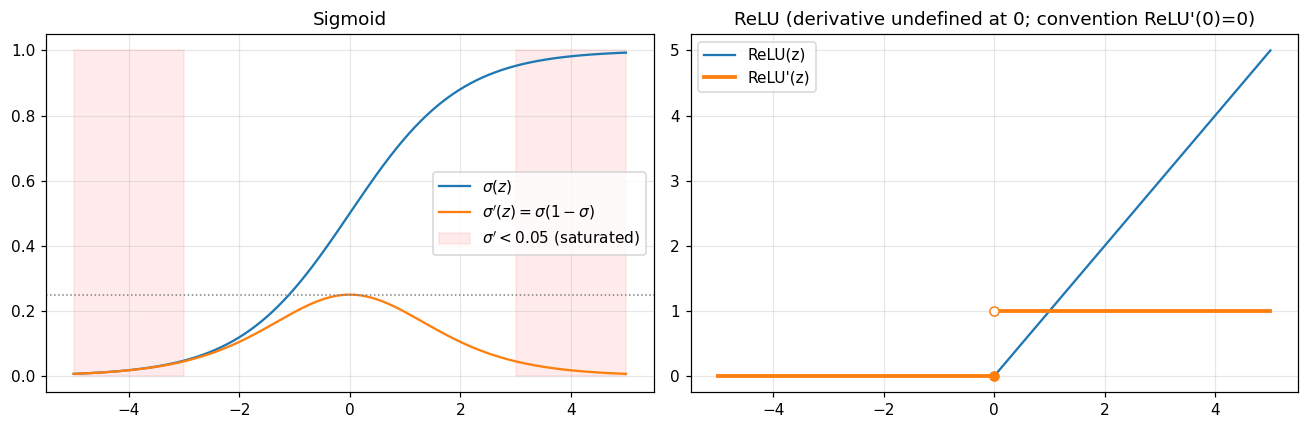

sigma'(0) = 0.2500
sigma'(2) = 0.1050
sigma'(3) = 0.0452
sigma'(5) = 0.0066


In [5]:
z = np.linspace(-5, 5, 1001)
sig = 1/(1 + np.exp(-z))
fig, axs = plt.subplots(1, 2, figsize=(12, 4))
# left: sigmoid and its derivative; derivative maxes out at 0.25 (dotted line)
axs[0].plot(z, sig, label=r"$\sigma(z)$"); axs[0].plot(z, sig*(1-sig), label=r"$\sigma'(z)=\sigma(1-\sigma)$")
axs[0].axhline(0.25, c="gray", ls=":", lw=1)
# shade |z| > 3, where the gradient is basically gone
axs[0].fill_between(z, 0, 1, where=np.abs(z) > 3, color="red", alpha=0.08, label=r"$\sigma'<0.05$ (saturated)")
axs[0].set_title("Sigmoid"); axs[0].legend()
# right: ReLU and its derivative as a step (0 for z<0, 1 for z>0)
axs[1].plot(z, np.maximum(0, z), label="ReLU(z)")
axs[1].plot(z[z < 0], 0*z[z < 0], "C1", lw=2.5, label="ReLU'(z)"); axs[1].plot(z[z > 0], 1 + 0*z[z > 0], "C1", lw=2.5)
# filled/open dots at z=0 to show the jump (using ReLU'(0)=0)
axs[1].plot([0], [0], "o", mfc="C1", mec="C1"); axs[1].plot([0], [1], "o", mfc="white", mec="C1")
axs[1].set_title("ReLU (derivative undefined at 0; convention ReLU'(0)=0)"); axs[1].legend()
plt.tight_layout(); plt.savefig("figs/1_3_activations.png"); plt.show()
# actual sigmoid' values to quote in part c
for zz in [0, 2, 3, 5]:
    s = 1/(1 + np.exp(-zz)); print(f"sigma'({zz}) = {s*(1-s):.4f}")

**c)** The sigmoid's derivative is at most 0.25 (at $z=0$) and gets tiny when $|z|$ is large: about 0.045 at $|z|=3$ and 0.0066 at $|z|=5$. Those are the saturated regions, where the sigmoid is basically flat at 0 or 1. During backprop the gradient gets multiplied by this derivative at every sigmoid unit it passes through, so a saturated unit passes back almost nothing, and its weights and everything before it barely update. Even in the best case each sigmoid layer cuts the gradient by at least 4x (ignoring the weights), so in a deep network it shrinks exponentially with depth. That's the vanishing gradient problem. ReLU's derivative is exactly 1 whenever the unit is on, so it doesn't shrink the gradient, but it's 0 when the unit is off, and a unit that's off for every input (a "dead ReLU") stops learning completely. That's probably what happened to the failed width-4 seeds in 1.2.

---
# 2 Computational Experiments: Approximating a Discontinuous Function

The target is the step function $H(x)$ on $[0,1]$, which jumps from 0 to 1 at $x=0.5$. Unless I say otherwise, every model uses 1000 evenly spaced training points, MSE loss, and Adam for 10k steps (learning rate decaying from $3\times10^{-3}$ to $10^{-5}$), with seed 0. I evaluate on a 4001-point grid using:
* **MSE**
* **max err far**: the largest error more than 0.05 away from the jump, to catch ringing
* **10–90 width**: how wide the transition is (the distance between where the fit crosses 0.1 and 0.9)
* **overshoot / undershoot**: how far the fit goes above 1 or below 0

The training points are 0.001 apart, so no model can be shown a jump sharper than that.

In [6]:
# step function, 0 before 0.5 and 1 after
H = lambda x: (x >= 0.5).astype(float)
xt2 = np.linspace(0, 1, 1000)[:, None]; yt2 = H(xt2)   # training data
xe = np.linspace(0, 1, 4001)[:, None]; ye = H(xe)      # finer grid for evaluation

# all the step-fit metrics for a prediction u on the eval grid
def step_metrics(u):
    u, x, y = u.ravel(), xe.ravel(), ye.ravel()
    far = np.abs(x - 0.5) > 0.05   # points away from the jump (to catch ringing)
    return {"MSE": np.mean((u - y)**2), "max err far": np.max(np.abs(u - y)[far]),
            # first x where u passes 0.9 minus first x where it passes 0.1
            "10-90 width": x[np.argmax(u > 0.9)] - x[np.argmax(u > 0.1)],
            "overshoot": max(u.max() - 1, 0.0), "undershoot": max(-u.min(), 0.0)}

# build + train one model on the step, print its metrics, return (prediction, metrics, loss history)
def run_step(name, sizes, act="tanh", loss="mse", seed=0, steps=10000):
    t = time.time(); net = MLP(sizes, act, seed=seed)
    hist = train(net, xt2, yt2, steps=steps, lr=3e-3, lr_final=1e-5, loss=loss)
    u = predict(net, xe, loss); m = step_metrics(u)
    print(f"{name:22s} " + "  ".join(f"{k} {v:.2e}" for k, v in m.items()) + f"   [{time.time()-t:.0f}s]")
    return u, m, hist

R = {}   # results for every model, keyed by name
R["tanh, 1x50 (baseline)"] = run_step("tanh, 1x50 (baseline)", [1, 50, 1])

tanh, 1x50 (baseline)  MSE 8.62e-03  max err far 7.66e-02  10-90 width 8.10e-02  overshoot 7.42e-02  undershoot 7.66e-02   [8s]


**a, b) Baseline: 1 hidden layer, 50 tanh units.**

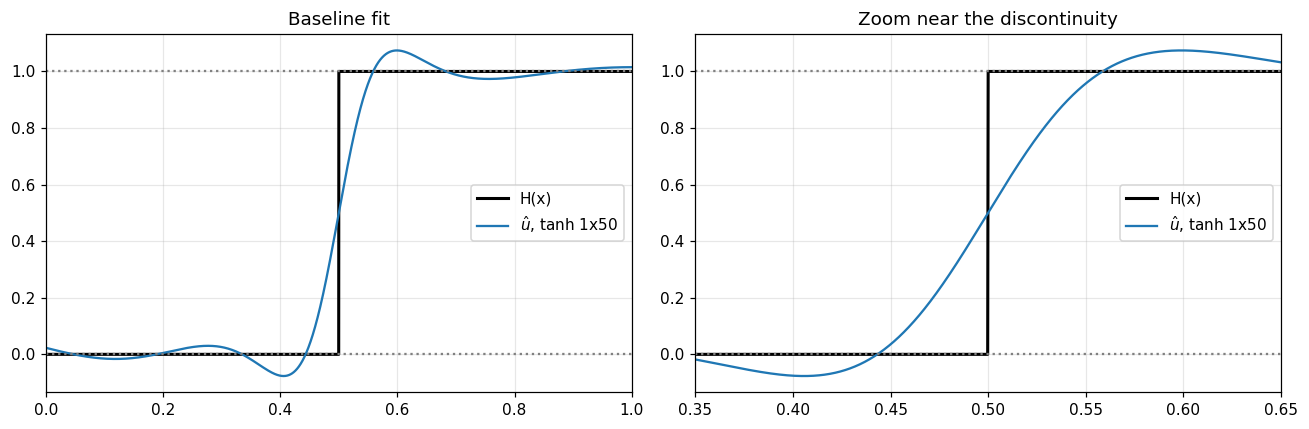

In [7]:
u0 = R["tanh, 1x50 (baseline)"][0]
# same plot twice: full range, then zoomed in on the jump
fig, axs = plt.subplots(1, 2, figsize=(12, 4))
for ax, lim in zip(axs, [(0, 1), (0.35, 0.65)]):
    ax.plot(xe, ye, "k", lw=2, label="H(x)"); ax.plot(xe, u0, "C0", label=r"$\hat u$, tanh 1x50")
    ax.axhline(1, c="gray", ls=":"); ax.axhline(0, c="gray", ls=":"); ax.set_xlim(*lim); ax.legend()
axs[0].set_title("Baseline fit"); axs[1].set_title("Zoom near the discontinuity")
plt.tight_layout(); plt.savefig("figs/2_1b_baseline.png"); plt.show()

Instead of a jump, the network makes a smooth ramp about 0.08 wide. Right next to the jump it overshoots above 1 and undershoots below 0 by about 7–8%, and then it keeps wiggling (ringing) for a good distance on both sides. This looks a lot like the Gibbs phenomenon, where a truncated Fourier series overshoots a step by about 9% and the overshoot never goes away no matter how many terms you add. The situation here is similar: a smooth function is being fit to a jump with least squares, and in part c making the network wider didn't reduce the overshoot either. It isn't exactly Gibbs, since the network can move its basis functions around and is also limited by how well it trains, but it's the same basic effect.

**c) Modifications, each applied independently to the baseline.** As an extra, I also combine depth with ReLU.

In [8]:
# change one thing at a time vs the baseline: width, depth, activation, loss
R["tanh, 1x200"]      = run_step("tanh, 1x200",      [1, 200, 1])
R["tanh, 1x500"]      = run_step("tanh, 1x500",      [1, 500, 1])
R["tanh, 3x50"]       = run_step("tanh, 3x50",       [1, 50, 50, 50, 1])
R["ReLU, 1x50"]       = run_step("ReLU, 1x50",       [1, 50, 1], act="relu")
R["tanh 1x50, L1"]    = run_step("tanh 1x50, L1",    [1, 50, 1], loss="l1")
R["tanh 1x50, Huber"] = run_step("tanh 1x50, Huber", [1, 50, 1], loss="huber")
R["tanh 1x50, BCE"]   = run_step("tanh 1x50, BCE",   [1, 50, 1], loss="bce")
R["(extra) ReLU, 3x50"] = run_step("(extra) ReLU, 3x50", [1, 50, 50, 50, 1], act="relu")

tanh, 1x200            MSE 7.29e-03  max err far 7.54e-02  10-90 width 6.93e-02  overshoot 7.24e-02  undershoot 7.54e-02   [32s]
tanh, 1x500            MSE 1.10e-02  max err far 1.23e-01  10-90 width 1.02e-01  overshoot 7.65e-02  undershoot 7.78e-02   [302s]
tanh, 3x50             MSE 2.12e-04  max err far 2.00e-03  10-90 width 2.25e-03  overshoot 5.35e-02  undershoot 5.50e-02   [265s]
ReLU, 1x50             MSE 2.43e-03  max err far 4.23e-03  10-90 width 2.33e-02  overshoot 1.69e-03  undershoot 8.93e-04   [8s]
tanh 1x50, L1          MSE 1.14e-02  max err far 1.50e-01  10-90 width 1.21e-01  overshoot 2.05e-02  undershoot 2.63e-02   [11s]
tanh 1x50, Huber       MSE 8.56e-03  max err far 6.82e-02  10-90 width 8.82e-02  overshoot 3.89e-02  undershoot 4.06e-02   [9s]
tanh 1x50, BCE         MSE 9.79e-04  max err far 4.75e-09  10-90 width 1.13e-02  overshoot 0.00e+00  undershoot 0.00e+00   [8s]
(extra) ReLU, 3x50     MSE 9.40e-05  max err far 2.29e-03  10-90 width 7.50e-04  overshoot 4.14e-0

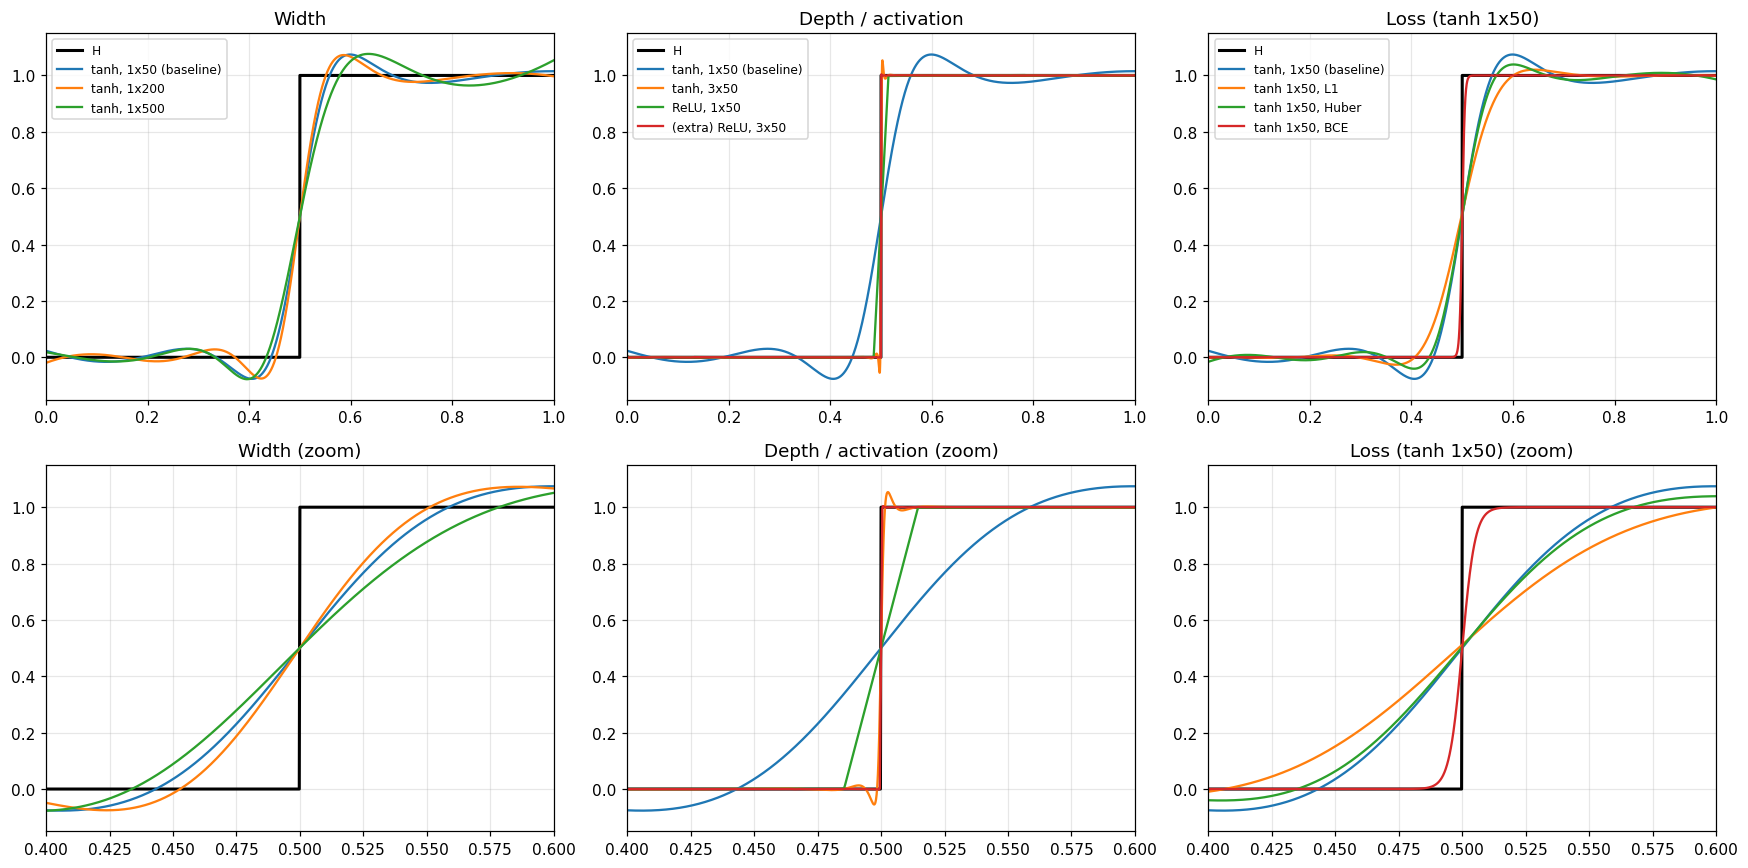

model                          MSE  maxerr far  10-90 width  overshoot undershoot
tanh, 1x50 (baseline)     8.62e-03    7.66e-02     8.10e-02   7.42e-02   7.66e-02
tanh, 1x200               7.29e-03    7.54e-02     6.93e-02   7.24e-02   7.54e-02
tanh, 1x500               1.10e-02    1.23e-01     1.02e-01   7.65e-02   7.78e-02
tanh, 3x50                2.12e-04    2.00e-03     2.25e-03   5.35e-02   5.50e-02
ReLU, 1x50                2.43e-03    4.23e-03     2.33e-02   1.69e-03   8.93e-04
tanh 1x50, L1             1.14e-02    1.50e-01     1.21e-01   2.05e-02   2.63e-02
tanh 1x50, Huber          8.56e-03    6.82e-02     8.82e-02   3.89e-02   4.06e-02
tanh 1x50, BCE            9.79e-04    4.75e-09     1.13e-02   0.00e+00   0.00e+00
(extra) ReLU, 3x50        9.40e-05    2.29e-03     7.50e-04   4.14e-03   1.25e-03


In [9]:
# one column per type of change, each compared against the baseline
groups = [("Width", ["tanh, 1x50 (baseline)", "tanh, 1x200", "tanh, 1x500"]),
          ("Depth / activation", ["tanh, 1x50 (baseline)", "tanh, 3x50", "ReLU, 1x50", "(extra) ReLU, 3x50"]),
          ("Loss (tanh 1x50)", ["tanh, 1x50 (baseline)", "tanh 1x50, L1", "tanh 1x50, Huber", "tanh 1x50, BCE"])]
fig, axs = plt.subplots(2, 3, figsize=(16, 8))
for j, (title, keys) in enumerate(groups):
    for row, lim in enumerate([(0, 1), (0.4, 0.6)]):   # top row full range, bottom row zoomed
        ax = axs[row, j]; ax.plot(xe, ye, "k", lw=2, label="H")
        for k in keys: ax.plot(xe, R[k][0], label=k)
        ax.set_xlim(*lim); ax.set_ylim(-0.15, 1.15); ax.set_title(title + (" (zoom)" if row else ""))
        if row == 0: ax.legend(fontsize=8)
plt.tight_layout(); plt.savefig("figs/2_1c_modifications.png"); plt.show()

# summary table of every model
print(f"{'model':24s}{'MSE':>10s}{'maxerr far':>12s}{'10-90 width':>13s}{'overshoot':>11s}{'undershoot':>11s}")
for k, (_, m, _) in R.items():
    print(f"{k:24s}{m['MSE']:10.2e}{m['max err far']:12.2e}{m['10-90 width']:13.2e}{m['overshoot']:11.2e}{m['undershoot']:11.2e}")

**d) Analysis.**

A tanh network is built entirely out of smooth functions, so its output is always smooth no matter how big the network is, and it can never actually jump. The best it can do is a steep ramp, and a steep ramp needs very large weights, which gradient descent is slow to reach. On top of that, the best smooth fit to a step under MSE overshoots and rings near the jump. Making the net wider didn't help (the overshoot stayed around 7–8% at widths 50, 200, and 500), so the problem is the type of function tanh makes, not the size of the network.

Of the changes the assignment asked for, depth (3x50 tanh) gave the lowest MSE, about 40x below the baseline with a ramp about 36x sharper. Stacking layers multiplies slopes, so the network can get steep without any single weight being huge. It still overshot by about 5%, though. ReLU and BCE were the only changes that got rid of the overshoot. BCE does it because the output goes through a sigmoid and can't leave $[0,1]$, and ReLU does it because of its shape (see below). L1 and Huber reduced the overshoot a little but blurred the ramp. The best model overall was the extra one I tried, 3x50 ReLU, which had the lowest MSE, the sharpest transition, and essentially no overshoot.

This lines up with the smoothness difference. Compositions of tanh are $C^\infty$, so a tanh network has to either smear the jump out or ring around it, which is why the overshoot never went away with width and was still there with depth. A ReLU network is piecewise linear, so it can't make a true jump either, but two ReLUs make a clean ramp that's perfectly flat on both sides. That keeps the error right at the jump instead of spreading it out as ringing, and adding depth just makes the ramp steeper, which is why ReLU plus depth worked best.

---
# 3 Compositional Learning

$h(x)=f_{\text{linear}}(x)+f_{\text{high}}(x)$, with $f_{\text{linear}}=1+2x$ and $f_{\text{high}}=0.5\cos(20\pi x)$, which has 10 full periods on $[0,1]$.

## Part 1: Learning the high-frequency component

Width-64 tanh nets with 1 to 4 hidden layers, trained on 1000 points with Adam for 10k steps (learning rate $3\times10^{-3}$ down to $10^{-5}$), seed 0. Every depth gets the same number of training steps.

In [10]:
# h = straight-line trend + fast cosine (10 periods on [0,1])
f_lin  = lambda x: 1 + 2*x
f_high = lambda x: 0.5*np.cos(20*np.pi*x)
h      = lambda x: f_lin(x) + f_high(x)
xt3 = np.linspace(0, 1, 1000)[:, None]; xe3 = np.linspace(0, 1, 4001)[:, None]   # train / eval grids
rmse = lambda a, b: np.sqrt(np.mean((a - b)**2))

# fit just f_high with 1-4 hidden layers of 64 tanh, same steps for each
depth_nets, depth_hist = {}, {}
for d in [1, 2, 3, 4]:
    t = time.time(); net = MLP([1] + [64]*d + [1], "tanh", seed=0)
    depth_hist[d] = train(net, xt3, f_high(xt3), steps=10000, lr=3e-3, lr_final=1e-5)
    depth_nets[d] = net
    print(f"depth {d}: params {sum(p.size for p in net.params()):6d}   test RMSE {rmse(net(xe3), f_high(xe3)):.3e}   [{time.time()-t:.0f}s]")
# baseline to compare against: a net that just outputs 0 everywhere
print(f"(reference: predicting 0 everywhere gives RMSE {rmse(0*xe3, f_high(xe3)):.3f}, MSE {np.mean(f_high(xe3)**2):.3f})")

depth 1: params    193   test RMSE 3.533e-01   [11s]
depth 2: params   4353   test RMSE 2.020e-01   [130s]
depth 3: params   8513   test RMSE 8.914e-03   [343s]
depth 4: params  12673   test RMSE 5.718e-03   [505s]
(reference: predicting 0 everywhere gives RMSE 0.354, MSE 0.125)


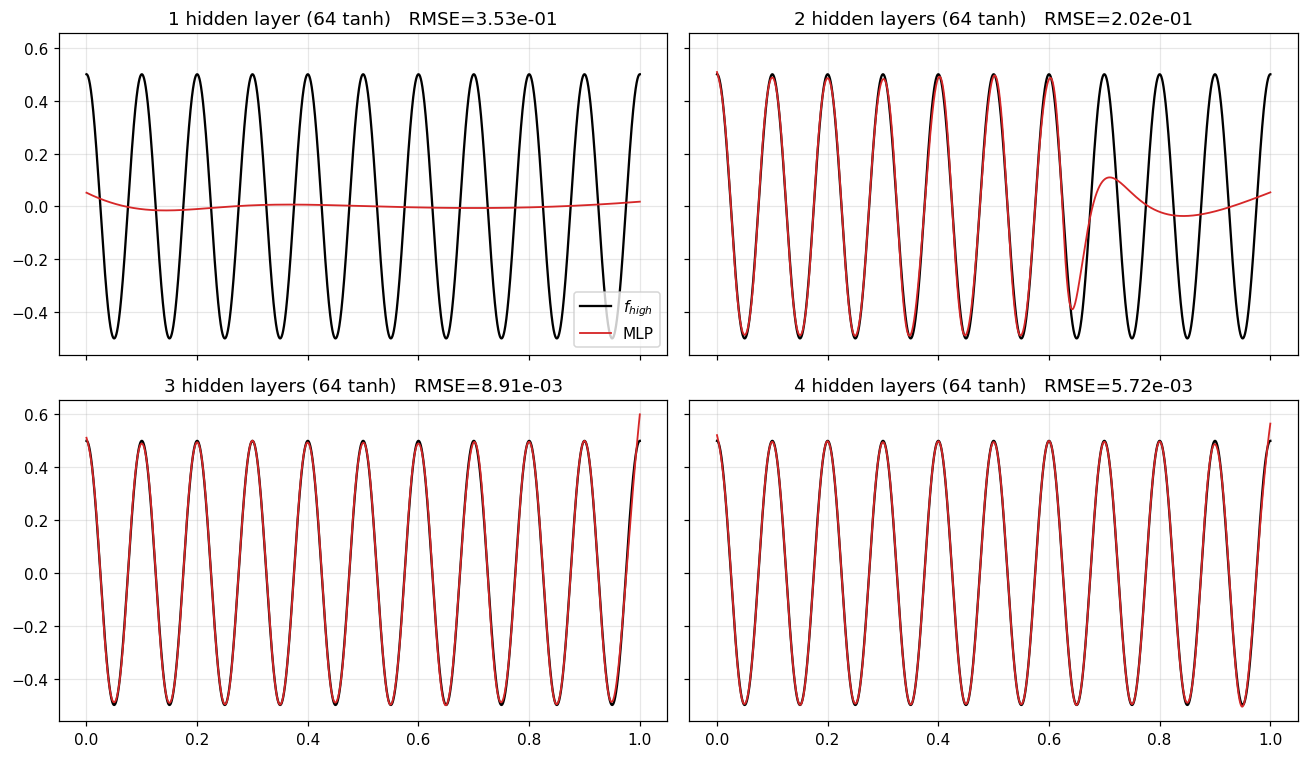

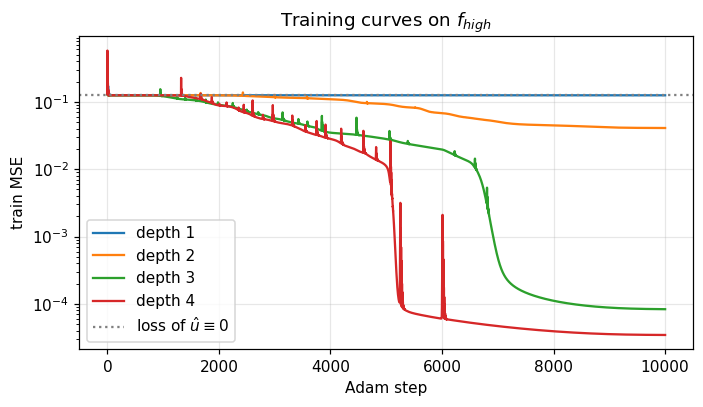

In [11]:
# 2x2 grid: fit for each depth
fig, axs = plt.subplots(2, 2, figsize=(12, 7), sharex=True, sharey=True)
for ax, d in zip(axs.ravel(), [1, 2, 3, 4]):
    ax.plot(xe3, f_high(xe3), "k", lw=1.5, label=r"$f_{high}$")
    ax.plot(xe3, depth_nets[d](xe3), "C3", lw=1.2, label="MLP")
    ax.set_title(f"{d} hidden layer{'s'*(d>1)} (64 tanh)   RMSE={rmse(depth_nets[d](xe3), f_high(xe3)):.2e}")
axs[0, 0].legend(loc="lower right"); plt.tight_layout(); plt.savefig("figs/3_1_depth_grid.png"); plt.show()

# loss curves; 0.125 line = loss of just predicting 0 (stuck on the plateau)
plt.figure(figsize=(6.5, 3.8))
for d in [1, 2, 3, 4]: plt.semilogy(depth_hist[d], label=f"depth {d}")
plt.axhline(0.125, c="gray", ls=":", label="loss of $\\hat u\\equiv 0$")
plt.xlabel("Adam step"); plt.ylabel("train MSE"); plt.legend(); plt.title("Training curves on $f_{high}$")
plt.tight_layout(); plt.savefig("figs/3_1_loss.png"); plt.show()

**b) Explanation via spectral bias.** Networks trained with gradient descent learn the low-frequency parts of a target first and the high-frequency parts much later, if at all. This is called spectral bias, and a 10-period cosine is exactly the kind of target that gets learned last. The 1-layer net stayed at MSE $\approx 0.125$ the whole run, which is the loss of just predicting 0, so it never learned the oscillation at all. The 2-layer net fit the first six periods and then fell apart after about $x=0.6$, and the 3- and 4-layer nets fit the whole thing to about $10^{-2}$ RMSE or better. Depth helps because each layer can fold the output of the layer before it, so the number of wiggles the network can make grows multiplicatively with depth, which seems to make high frequencies much easier to train. Deeper nets also have more parameters (193 for depth 1 vs 12,673 for depth 4), but extra width alone didn't help a shallow tanh net in Section 2, so it looks like the layers themselves matter, not just the parameter count.

## Part 2: Composition by "stitching" networks

**a) Modular training.** $N_{\text{linear}}$ is a small shallow net (one hidden layer of 8 tanh units) trained on $f_{\text{linear}}$ for 3k steps. $N_{\text{high}}$ is the same deep net as depth 4 in Part 1 (4x64 tanh), trained on $f_{\text{high}}$ for 10k steps. So the stitched model costs 13k steps in total. I do this for 3 seeds.

**b) Manual composition.** The stitched model just adds the two together, $\hat h_{\text{stitched}}(x)=N_{\text{linear}}(x)+N_{\text{high}}(x)$, using the `Stitched` class below.

**c) End-to-end baseline.** A single 4x64 tanh net trained directly on $h$ for the same 13k total steps, over the same 3 seeds. The plots compare the best seed of each approach, and the loss plot shows all six runs.

In [12]:
class Stitched:
    """h_stitched(x) = N_linear(x) + N_high(x)"""
    def __init__(self, *nets): self.nets = nets
    def __call__(self, x): return sum(n(x) for n in self.nets)

# stitched approach: train each piece on its own target, then add them
stitched, high_hist = {}, {}
for s in [0, 1, 2]:
    t = time.time()
    # small shallow net for the line (3k steps)
    N_lin = MLP([1, 8, 1], "tanh", seed=s)
    train(N_lin, xt3, f_lin(xt3), steps=3000, lr=3e-2, lr_final=1e-5)
    # deep net for the cosine (10k steps)
    N_high = MLP([1, 64, 64, 64, 64, 1], "tanh", seed=s)
    high_hist[s] = train(N_high, xt3, f_high(xt3), steps=10000, lr=3e-3, lr_final=1e-5)
    stitched[s] = Stitched(N_lin, N_high)
    # error of each piece and of the sum
    print(f"stitched seed {s}: N_linear RMSE on f_lin {rmse(N_lin(xe3), f_lin(xe3)):.3e}   "
          f"N_high RMSE on f_high {rmse(N_high(xe3), f_high(xe3)):.3e}   "
          f"stitched RMSE on h {rmse(stitched[s](xe3), h(xe3)):.3e}   [{time.time()-t:.0f}s]")

# end-to-end: one deep net trained directly on h, 13k steps = same total as stitched (3k + 10k)
e2e, e2e_hist = {}, {}
for s in [0, 1, 2]:
    t = time.time(); net = MLP([1, 64, 64, 64, 64, 1], "tanh", seed=s)
    e2e_hist[s] = train(net, xt3, h(xt3), steps=13000, lr=3e-3, lr_final=1e-5); e2e[s] = net
    # also print loss at steps 2k/5k/8k to see when it gets off the plateau
    print(f"end-to-end seed {s}: RMSE on h {rmse(net(xe3), h(xe3)):.3e}   "
          f"train MSE @ step 2k/5k/8k: {e2e_hist[s][1999]:.3f}/{e2e_hist[s][4999]:.3f}/{e2e_hist[s][7999]:.4f}   [{time.time()-t:.0f}s]")

stitched seed 0: N_linear RMSE on f_lin 4.409e-03   N_high RMSE on f_high 5.718e-03   stitched RMSE on h 7.250e-03   [426s]
stitched seed 1: N_linear RMSE on f_lin 3.743e-03   N_high RMSE on f_high 9.194e-03   stitched RMSE on h 9.958e-03   [383s]
stitched seed 2: N_linear RMSE on f_lin 2.795e-03   N_high RMSE on f_high 5.679e-03   stitched RMSE on h 6.344e-03   [382s]
end-to-end seed 0: RMSE on h 9.541e-03   train MSE @ step 2k/5k/8k: 0.125/0.114/0.0449   [518s]
end-to-end seed 1: RMSE on h 8.653e-03   train MSE @ step 2k/5k/8k: 0.125/0.081/0.0206   [687s]
end-to-end seed 2: RMSE on h 4.288e-03   train MSE @ step 2k/5k/8k: 0.125/0.072/0.0001   [686s]


stitched   RMSE on h: 7.25e-03  9.96e-03  6.34e-03   median 7.25e-03
end-to-end RMSE on h: 9.54e-03  8.65e-03  4.29e-03   median 8.65e-03


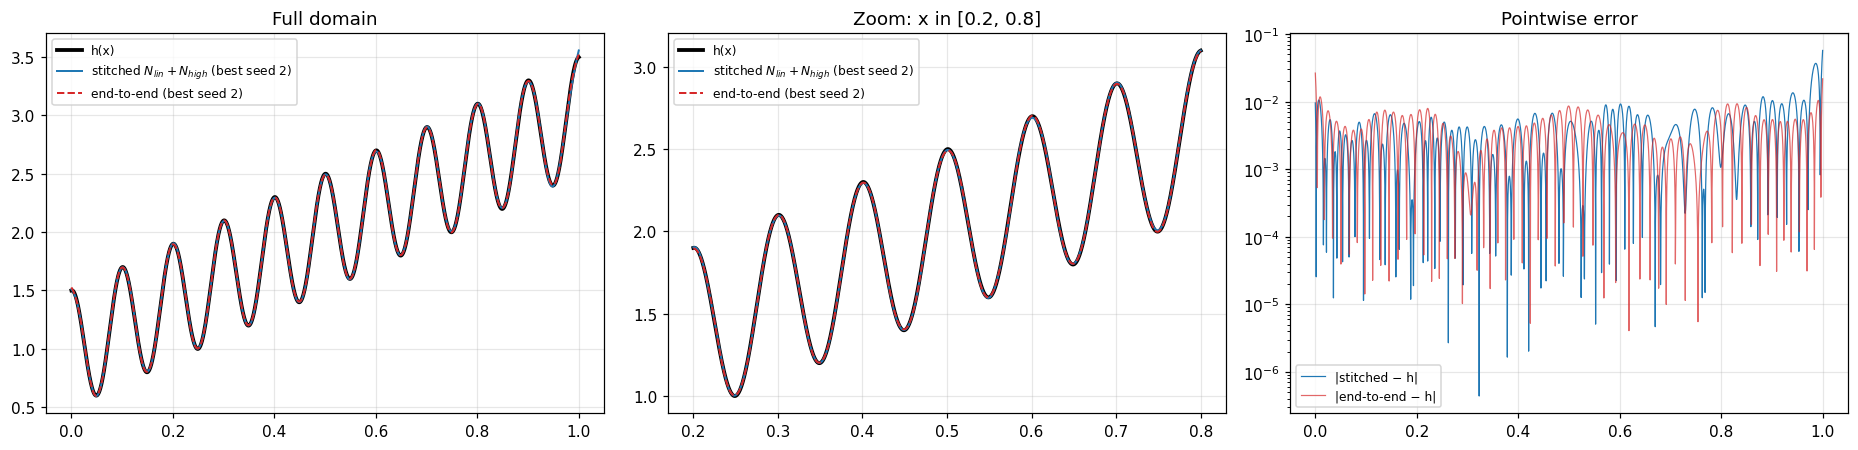

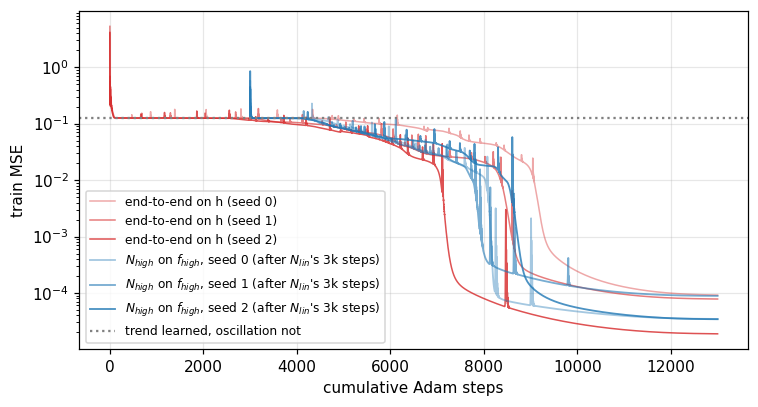

In [13]:
# RMSE on h for every seed of both approaches, plus the median
err_h = lambda net: rmse(net(xe3), h(xe3))
print(f"stitched   RMSE on h: " + "  ".join(f"{err_h(stitched[s]):.2e}" for s in stitched) + f"   median {np.median([err_h(n) for n in stitched.values()]):.2e}")
print(f"end-to-end RMSE on h: " + "  ".join(f"{err_h(e2e[s]):.2e}" for s in e2e) + f"   median {np.median([err_h(n) for n in e2e.values()]):.2e}")

# pick the best seed of each approach to plot
best_st = min(stitched, key=lambda s: err_h(stitched[s]))
best = min(e2e, key=lambda s: err_h(e2e[s]))
# panels 1-2: fits (full range + zoom), panel 3: pointwise error on a log scale
fig, axs = plt.subplots(1, 3, figsize=(17, 4.2))
for ax, lim, ttl in [(axs[0], (0, 1), "Full domain"), (axs[1], (0.2, 0.8), "Zoom: x in [0.2, 0.8]")]:
    m = (xe3.ravel() >= lim[0]) & (xe3.ravel() <= lim[1])   # only the points inside this x range
    ax.plot(xe3[m], h(xe3[m]), "k", lw=2.5, label="h(x)")
    ax.plot(xe3[m], stitched[best_st](xe3[m]), "C0", lw=1.3, label=f"stitched $N_{{lin}}+N_{{high}}$ (best seed {best_st})")
    ax.plot(xe3[m], e2e[best](xe3[m]), "C3--", lw=1.3, label=f"end-to-end (best seed {best})")
    ax.set_title(ttl); ax.legend(fontsize=8)
axs[2].semilogy(xe3, np.abs(stitched[best_st](xe3) - h(xe3)), "C0", lw=0.8, label="|stitched − h|")
axs[2].semilogy(xe3, np.abs(e2e[best](xe3) - h(xe3)), "C3", lw=0.8, alpha=0.7, label="|end-to-end − h|")
axs[2].set_title("Pointwise error"); axs[2].legend(fontsize=8)
plt.tight_layout(); plt.savefig("figs/3_2_stitched_vs_e2e.png"); plt.show()

# loss curves for all 6 runs; N_high is shifted right by 3k steps since N_lin trains first
plt.figure(figsize=(7, 3.8))
for s in e2e_hist: plt.semilogy(e2e_hist[s], "C3", alpha=0.4 + 0.2*s, lw=1, label=f"end-to-end on h (seed {s})")
for s in high_hist: plt.semilogy(np.arange(3000, 13000), high_hist[s], "C0", alpha=0.4 + 0.2*s, lw=1.2, label=f"$N_{{high}}$ on $f_{{high}}$, seed {s} (after $N_{{lin}}$'s 3k steps)")
plt.axhline(0.125, c="gray", ls=":", label="trend learned, oscillation not")
plt.xlabel("cumulative Adam steps"); plt.ylabel("train MSE"); plt.legend(fontsize=8)
plt.tight_layout(); plt.savefig("figs/3_2_loss.png"); plt.show()

**Discussion.** Both approaches fit $h$ well, to an RMSE under $10^{-2}$, and both fits look identical to $h$ by eye. Over 3 seeds:

| | seed 0 | seed 1 | seed 2 | median | worst / best |
|---|---|---|---|---|---|
| stitched | 7.3e-3 | 1.0e-2 | 6.3e-3 | 7.3e-3 | 1.6× |
| end-to-end | 9.5e-3 | 8.7e-3 | 4.3e-3 | 8.7e-3 | 2.2× |

Both approaches run into the same spectral-bias problem. The end-to-end net learns the line $1+2x$ within a few hundred steps and then sits at MSE $\approx 0.125$ (trend learned, cosine not), and $N_{\text{high}}$ gets stuck at the same spot at first. Taking the trend out helped: $N_{\text{high}}$ dropped to a near-perfect fit after about 5–5.5k of its own steps, while the end-to-end nets needed about 7–9k, so roughly 1.5x faster, but the plateau was still there. Stitching had the better median and a smaller spread between seeds (1.6x vs 2.2x), while end-to-end had the single best run (seed 2) and the least predictable timing: seed 0 was still at MSE 0.11 at step 5k and didn't converge until about 9k steps. The worst runs of the two were about the same (1.0e-2 vs 9.5e-3). Stitching also lets you check each piece on its own. The catch is that stitching only works here because we already know how to split $h$ into a line plus a cosine. With real data you usually only see $h$ and would have to figure out that split yourself.

Overall the accuracy is close. When the decomposition is known, I think stitching is the more effective approach because it's more consistent and easier to verify, but it doesn't fix spectral bias, since the deep net still needs thousands of steps to learn the oscillation.

---
# 4 Regularization: L1 vs. L2

The data are 40 evenly spaced points on $[0,2\pi]$ with $y=\sin x$ plus Gaussian noise (std 0.1, seed 0). The model is a weighted sum of 100 Gaussian bumps (width 0.5, centers evenly spaced on $[0,2\pi]$), fit by minimizing the mean squared error plus $\lambda$ times the penalty.

* **L2 (ridge)** has a closed-form solution, so I just solve the linear system.
* **L1 (lasso)** has no closed form, so I solve it with FISTA (gradient descent plus soft thresholding, with momentum) and check it against sklearn's `Lasso`. Sklearn scales the loss differently, so its $\alpha$ is $\lambda/2$.

RMSE is measured against the true $\sin x$ on a 2000-point grid, not against the noisy data.

In [14]:
from sklearn.linear_model import Lasso
rng = np.random.default_rng(0)
# 40 noisy readings of sin(x)
n = 40
x4 = np.linspace(0, 2*np.pi, n); y4 = np.sin(x4) + rng.normal(0, 0.1, n)
# 100 Gaussian bumps -> feature matrix Phi (rows = points, cols = bumps)
centers = np.linspace(0, 2*np.pi, 100); ell = 0.5
features = lambda x: np.exp(-(x[:, None] - centers[None, :])**2 / (2*ell**2))
A = features(x4); xg = np.linspace(0, 2*np.pi, 2000); Ag = features(xg)   # A = training Phi, Ag = Phi on a fine grid
rmse_sin = lambda w: np.sqrt(np.mean((Ag @ w - np.sin(xg))**2))           # error vs the true sin, not the noisy data

# soft thresholding: shrink toward 0 by tau, anything within tau of 0 becomes exactly 0
def soft(v, tau): return np.sign(v) * np.maximum(np.abs(v) - tau, 0.0)

# lasso via FISTA: gradient step on the MSE part, soft threshold, then momentum
def fista_l1(A, y, lam, iters=20000):
    n = len(y); Lip = 2*np.linalg.norm(A, 2)**2 / n      # Lipschitz const. of the smooth part's gradient
    w = np.zeros(A.shape[1]); z = w.copy(); t = 1.0
    for _ in range(iters):
        w_new = soft(z - (2*A.T @ (A @ z - y) / n) / Lip, lam / Lip)
        # Nesterov momentum: extrapolate past w_new a bit
        t_new = (1 + np.sqrt(1 + 4*t*t)) / 2
        z = w_new + (t - 1) / t_new * (w_new - w); w, t = w_new, t_new
    return w

# ridge has a closed form, just solve the linear system
def ridge(A, y, lam):
    n = len(y); return np.linalg.solve(A.T @ A / n + lam*np.eye(A.shape[1]), A.T @ y / n)

# how badly conditioned Phi is (explains part a)
print(f"Phi is 40x100, numerical rank {np.linalg.matrix_rank(A)}, condition number {np.linalg.cond(A):.1e}")

Phi is 40x100, numerical rank 37, condition number 8.7e+15


**a) No penalty.** There are 100 weights and only 40 data points, so infinitely many weight vectors fit the data equally well. `np.linalg.lstsq` picks the one with the smallest norm.

train max residual 0.044   max|w| = 3.03e+10   RMSE vs sin = 0.700


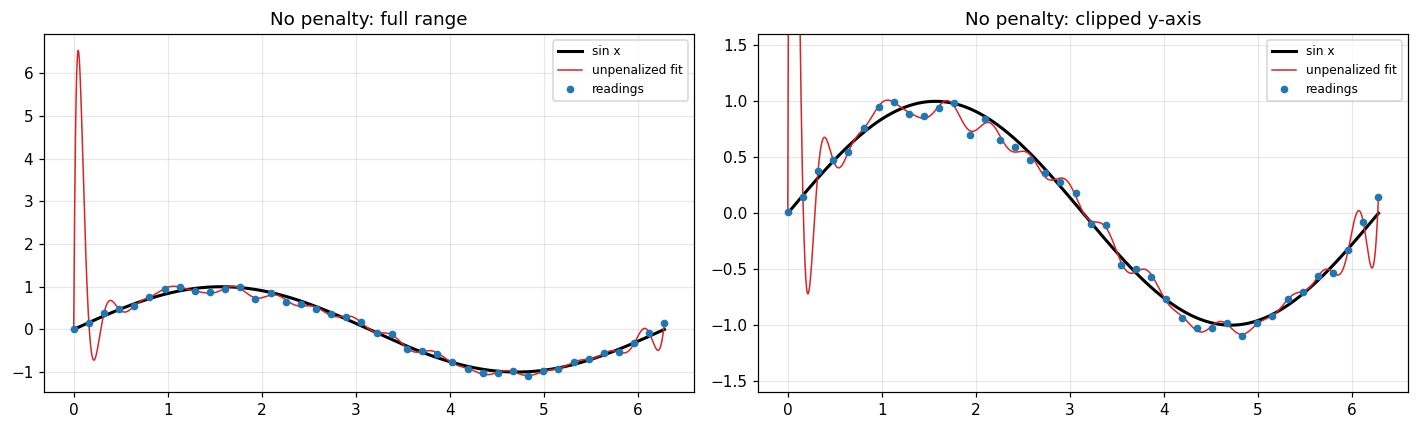

In [15]:
# no penalty: min-norm least squares
w_free = np.linalg.lstsq(A, y4, rcond=None)[0]
print(f"train max residual {np.max(np.abs(A @ w_free - y4)):.3f}   max|w| = {np.abs(w_free).max():.2e}   RMSE vs sin = {rmse_sin(w_free):.3f}")
# left: full y-range (shows the blow-up), right: y clipped to see the wiggles
fig, axs = plt.subplots(1, 2, figsize=(13, 4))
for ax, ylim in zip(axs, [None, (-1.6, 1.6)]):
    ax.plot(xg, np.sin(xg), "k", lw=2, label="sin x"); ax.plot(xg, Ag @ w_free, "C3", lw=1, label="unpenalized fit")
    ax.plot(x4, y4, "o", c="C0", ms=4, label="readings")
    if ylim: ax.set_ylim(*ylim)
    ax.legend(fontsize=8)
axs[0].set_title("No penalty: full range"); axs[1].set_title("No penalty: clipped y-axis")
plt.tight_layout(); plt.savefig("figs/4a_unpenalized.png"); plt.show()

At the readings the fit basically matches the data, noise included (the max training residual is 0.044, below the noise level of 0.1). Between the readings it wanders away from $\sin x$, and near the ends it blows up, spiking to about 6.5 just after $x=0$. The RMSE against $\sin x$ is 0.70, seven times the noise level. This happens because there are more weights than data points and neighboring bumps are almost identical, so the problem is extremely ill-conditioned (condition number around $10^{16}$). To fit the noise, the solver puts huge positive and negative weights (around $10^{10}$) on neighboring bumps that cancel out at the data points, but nothing in the loss controls what those weights do in between, so you get large oscillations there. It's worst near the ends because the bumps there only have data on one side.

**b) L2 and L1 for $\lambda\in\{10^{-4},10^{-3},10^{-2},10^{-1}\}$.**

  lambda |   RMSE L2 |   RMSE L1 | #zeros L2 | #zeros L1 | #zeros sklearn | rel. objective gap FISTA vs sklearn


/Users/vicky/ENTER/lib/python3.13/site-packages/sklearn/linear_model/_coordinate_descent.py:695: ConvergenceWarning: Objective did not converge. You might want to increase the number of iterations, check the scale of the features or consider increasing regularisation. Duality gap: 3.466e-08, tolerance: 1.917e-09
  model = cd_fast.enet_coordinate_descent(


   1e-04 |    0.0539 |    0.0540 |         0 |        85 |             85 |                             2.9e-07
   1e-03 |    0.0526 |    0.0533 |         0 |        87 |             87 |                             1.4e-08


/Users/vicky/ENTER/lib/python3.13/site-packages/sklearn/linear_model/_coordinate_descent.py:695: ConvergenceWarning: Objective did not converge. You might want to increase the number of iterations, check the scale of the features or consider increasing regularisation. Duality gap: 2.953e-08, tolerance: 1.917e-09
  model = cd_fast.enet_coordinate_descent(


   1e-02 |    0.0514 |    0.0677 |         0 |        90 |             90 |                             3.1e-09
   1e-01 |    0.0577 |    0.2661 |         0 |        94 |             94 |                             1.3e-11


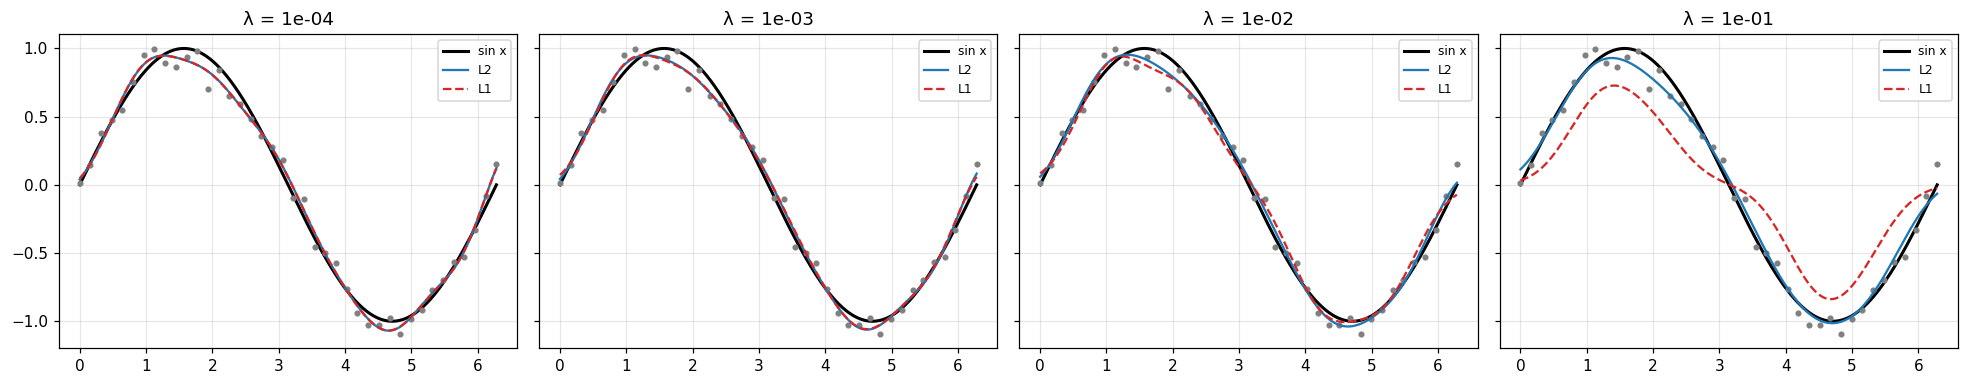

In [16]:
lams = [1e-4, 1e-3, 1e-2, 1e-1]; W2, W1 = {}, {}   # W2 = ridge weights, W1 = lasso weights, per lambda
J_l1 = lambda w, lam: np.mean((A @ w - y4)**2) + lam*np.abs(w).sum()   # lasso objective, to compare solvers
print(f"{'lambda':>8s} | {'RMSE L2':>9s} | {'RMSE L1':>9s} | {'#zeros L2':>9s} | {'#zeros L1':>9s} | "
      f"{'#zeros sklearn':>14s} | {'rel. objective gap FISTA vs sklearn':>35s}")
for lam in lams:
    W2[lam] = ridge(A, y4, lam); W1[lam] = fista_l1(A, y4, lam)
    # sanity check FISTA against sklearn (sklearn's alpha = lambda/2 because of its 1/(2n) scaling)
    w_sk = Lasso(alpha=lam/2, fit_intercept=False, max_iter=10**6, tol=1e-10).fit(A, y4).coef_
    gap = abs(J_l1(W1[lam], lam) - J_l1(w_sk, lam)) / J_l1(w_sk, lam)
    print(f"{lam:8.0e} | {rmse_sin(W2[lam]):9.4f} | {rmse_sin(W1[lam]):9.4f} | {np.sum(W2[lam] == 0):9d} | "
          f"{np.sum(W1[lam] == 0):9d} | {np.sum(w_sk == 0):14d} | {gap:35.1e}")

# one panel per lambda: L2 vs L1 fit against the true sin
fig, axs = plt.subplots(1, 4, figsize=(18, 3.6), sharey=True)
for ax, lam in zip(axs, lams):
    ax.plot(xg, np.sin(xg), "k", lw=2, label="sin x"); ax.plot(x4, y4, "o", c="gray", ms=3)
    ax.plot(xg, Ag @ W2[lam], "C0", label="L2"); ax.plot(xg, Ag @ W1[lam], "C3--", label="L1")
    ax.set_title(f"λ = {lam:.0e}"); ax.legend(fontsize=8)
plt.tight_layout(); plt.savefig("figs/4b_fits.png"); plt.show()

**RMSE against $\sin x$** (unpenalized fit: 0.70):

| $\lambda$ | L2 | L1 |
|---|---|---|
| $10^{-4}$ | 0.054 | 0.054 |
| $10^{-3}$ | 0.053 | 0.053 |
| $10^{-2}$ | 0.051 | 0.068 |
| $10^{-1}$ | 0.058 | 0.266 |

Every penalized fit gets rid of the blow-up from part a. L2 barely cares about $\lambda$ here, with RMSE between 0.051 and 0.058 for all four values, about half the noise level. L1 matches L2 for $\lambda\le10^{-3}$, is a bit worse at $10^{-2}$ (0.068), and underfits badly at $10^{-1}$ (0.266) because it keeps only 6 bumps and shrinks them, so the peaks get flattened. For a smooth target like this with lots of overlapping bumps, L2 is the more forgiving choice.

FISTA and sklearn agree on the objective value, the number of zeros, and the RMSE at every $\lambda$. Individual weights can differ slightly because neighboring bumps are nearly interchangeable, which is also why sklearn gives a convergence warning at a couple of the $\lambda$ values.

**c) Weights at $\lambda=10^{-2}$.**

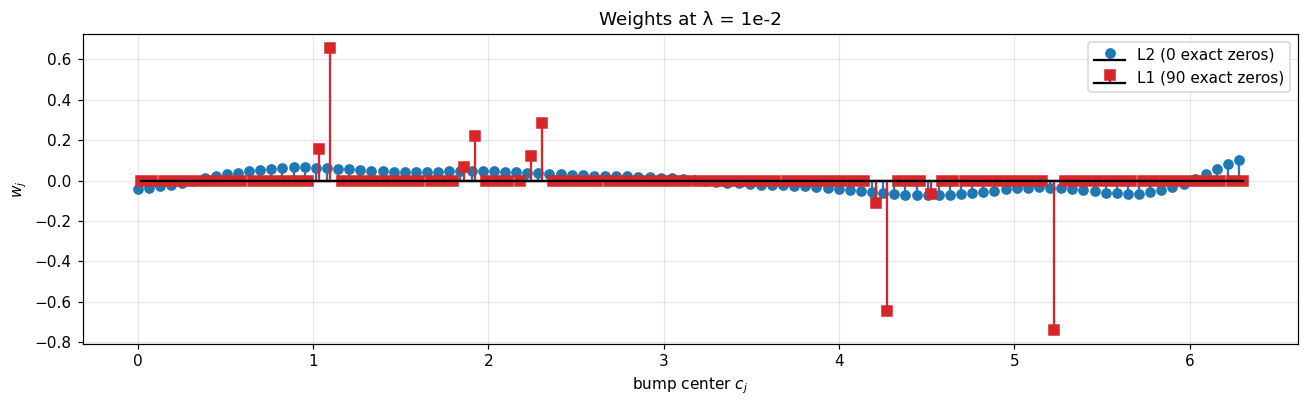

L2: exact zeros = 0   (smallest |w| = 5.0e-04)
L1: exact zeros = 90   nonzero weights at centers: [1.02 1.08 1.84 1.9  2.22 2.28 4.19 4.25 4.51 5.2 ]


In [17]:
lam = 1e-2
# stem plot of all 100 weights; L1 shifted right a little so the stems don't overlap
fig, ax = plt.subplots(figsize=(12, 3.8))
ax.stem(centers, W2[lam], linefmt="C0-", markerfmt="C0o", basefmt="k-", label=f"L2 ({np.sum(W2[lam]==0)} exact zeros)")
ax.stem(centers + 0.02, W1[lam], linefmt="C3-", markerfmt="C3s", basefmt="k-", label=f"L1 ({np.sum(W1[lam]==0)} exact zeros)")
ax.set_xlabel("bump center $c_j$"); ax.set_ylabel("$w_j$"); ax.legend(); ax.set_title("Weights at λ = 1e-2")
plt.tight_layout(); plt.savefig("figs/4c_weights.png"); plt.show()
# count exact zeros, and list which bumps L1 kept
print("L2: exact zeros =", np.sum(W2[lam] == 0), f"  (smallest |w| = {np.abs(W2[lam]).min():.1e})")
print("L1: exact zeros =", np.sum(W1[lam] == 0), "  nonzero weights at centers:", np.round(centers[W1[lam] != 0], 2))

 L2 gives 0 exact zeros and all 100 weights are small but nonzero. L1 gives 90 exact zeros, so only 10 bumps are used. The difference comes from how each penalty pushes on small weights. The L2 penalty's push toward zero gets weaker as the weight gets smaller, so there's never a reason to set a weight exactly to zero, and they all just shrink. The L1 penalty pushes with the same strength no matter how small the weight is, so whenever a bump isn't helping the fit enough to outweigh that push, it's cheaper to set it exactly to zero (in FISTA, the soft-thresholding step does this directly). Since neighboring bumps are nearly redundant, L1 keeps only a few per region and drops the rest. The result is a much simpler model where 10 bumps fit $\sin x$ almost as well as all 100 (RMSE 0.068 vs 0.051 for L2).